In [11]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('data_core.csv')

numerical_cols = ['Temparature', 'Humidity', 'Moisture', 'Nitrogen', 'Potassium', 'Phosphorous']
df[numerical_cols].describe()

,Temparature,Humidity,Moisture,Nitrogen,Potassium,Phosphorous
count,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000
mean,30.338895,59.210731,43.580862,18.429125,3.916375,18.512500
std,4.478262,8.177366,12.596156,11.852406,5.494807,13.244113
min,20.000000,40.020000,20.000000,0.000000,0.000000,0.000000
25%,27.050000,53.277500,33.967500,9.000000,0.000000,8.000000
50%,30.240000,59.110000,42.250000,14.000000,1.000000,18.000000
75%,33.460000,65.082500,52.950000,26.000000,5.000000,30.000000
max,40.000000,80.000000,70.000000,46.000000,23.000000,46.000000


In [12]:
Q1 = df['Potassium'].quantile(0.25)
Q3 = df['Potassium'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[(df['Potassium'] < lower_bound) | (df['Potassium'] > upper_bound)]

print("Q1 (25%):", Q1)
print("Q3 (75%):", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)
print("Number of flagged outliers:", len(outliers))

Q1 (25%): 0.0
Q3 (75%): 5.0
IQR: 5.0
Lower Bound: -7.5
Upper Bound: 12.5
Number of flagged outliers: 910


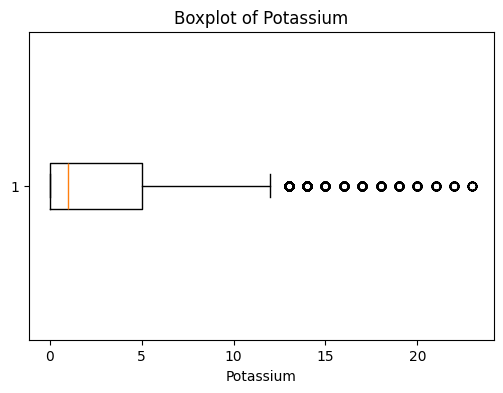

In [13]:
plt.figure(figsize=(6,4))
plt.boxplot(df['Potassium'], vert=False)
plt.title('Boxplot of Potassium')
plt.xlabel('Potassium')
plt.show()

In [14]:
print("Summary of flagged Potassium values:")
print(outliers['Potassium'].describe())

print("\nValue counts of flagged Potassium values:")
print(outliers['Potassium'].value_counts().sort_index())

print("\nOverall Potassium range in dataset:", df['Potassium'].min(), "-", df['Potassium'].max())

Summary of flagged Potassium values:
count    910.000000
mean      16.340659
std        2.796823
min       13.000000
25%       14.000000
50%       16.000000
75%       18.000000
max       23.000000
Name: Potassium, dtype: float64

Value counts of flagged Potassium values:
Potassium
13    163
14    152
15    107
16     96
17    100
18     77
19     70
20     52
21     38
22     37
23     18
Name: count, dtype: int64

Overall Potassium range in dataset: 0 - 23


### Decision: KEEP the flagged Potassium values

The flagged values (13–23) are not negative or impossible; they fall within
the dataset's natural maximum (23). The distribution is right-skewed because
most crops require low Potassium, so IQR statistically flags the higher,
legitimate values as outliers. Since these represent real agricultural
measurements (crops/fertilizers needing more Potassium) and not data entry
errors, no removal, capping, or transformation is applied — the values are
kept as-is.

In [15]:
print("Final decision: No treatment applied to Potassium.")
print("Original dataset (data_core.csv) remains unmodified.")
print(df['Potassium'].describe())

Final decision: No treatment applied to Potassium.
Original dataset (data_core.csv) remains unmodified.
count    8000.000000
mean        3.916375
std         5.494807
min         0.000000
25%         0.000000
50%         1.000000
75%         5.000000
max        23.000000
Name: Potassium, dtype: float64
